# Entrenamiento del modelo de inasistencia (módulo Citas)

Este cuaderno muestra, **paso a paso**, cómo se entrena y evalúa el modelo que estima la probabilidad de que
un estudiante no asista a una cita. Es la versión explicada de `train_no_show.py`: reutiliza sus funciones
(mismos datos, mismas variables, mismas métricas) y **no guarda ni sobrescribe** ningún archivo.

**Técnica:** regresión logística con calibración de Platt, comparada con reglas simples y con *gradient boosting*.
**Uso permitido:** solo para decidir recordatorios; nunca para negar ni retrasar una cita.

Para ejecutarlo, desde `services/citas` y con el entorno virtual activo, hace falta el conjunto de datos en
`ml/data/appointments.rda` (no se versiona; ver `README.md`):

```bash
python -m pip install -r ml/requirements.txt
```

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_curve

ML = Path.cwd() if (Path.cwd() / "train_no_show.py").exists() else Path("ml").resolve()
sys.path.insert(0, str(ML))          # train_no_show.py
sys.path.insert(0, str(ML.parent))   # src/ del servicio Citas
import train_no_show as tns

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
AZUL, CLARO, GRIS = "#244A7C", "#8FA9CC", "#9AA3B2"
pd.set_option("display.max_columns", 20)
print("Variables del modelo:", tns.FEATURES)

Variables del modelo: ['lead_log', 'same_day', 'prior_no_shows']


## 1. Datos

*Medical Appointment No Shows* (Joni Hoppen, Kaggle): 110 527 citas de hospitales públicos de Vitória (Brasil, 2016).
Se descartan las filas con fechas inconsistentes (la cita antes de haberse agendado) y las edades inválidas.
No son datos de estudiantes: se usan para **validar el proceso** de entrenamiento y evaluación.

In [2]:
df = tns.cargar()
cols = ["PatientId", "Gender", "Age", "ScheduledDay", "AppointmentDay", "Scholarship", "No_show"]
display(df[cols].head())
print(f"Tasa global de inasistencia: {df['y'].mean():.1%}")

Filas: 110527 -> 110516 (se descartan fechas inconsistentes y edades inválidas)


,PatientId,Gender,Age,ScheduledDay,AppointmentDay,Scholarship,No_show
0,2.987250e+13,Male,62.0,2016-04-29 18:38:08,2016-04-29,0.0,No
1,5.589980e+14,Female,56.0,2016-04-29 16:08:27,2016-04-29,0.0,No
2,4.262960e+12,Male,62.0,2016-04-29 16:19:04,2016-04-29,0.0,No
3,8.679510e+11,Male,8.0,2016-04-29 17:29:31,2016-04-29,0.0,No
4,8.841190e+12,Male,56.0,2016-04-29 16:07:23,2016-04-29,0.0,No


Tasa global de inasistencia: 20.2%


## 2. Variables

El modelo usa solo **tres variables de comportamiento de agenda** que el servicio Citas también conoce:

| Variable | Qué mide |
|---|---|
| `lead_log` | logaritmo de (1 + días entre agendar y la cita, con tope de 60) |
| `same_day` | 1 si la cita se agendó para el mismo día |
| `prior_no_shows` | inasistencias previas del paciente (con tope de 3) |

**Edad, sexo, barrio y beca no entran al modelo**: se usan únicamente para auditar la equidad (sección 7).

**Sin fuga de información:** una inasistencia previa solo cuenta si esa cita ocurrió *antes* de que se agendara la actual.

,lead_log,same_day,prior_no_shows,lead_days,y
count,110516.000,110516.000,110516.000,110516.000,110516.000
mean,1.541,0.349,0.123,10.184,0.202
std,1.366,0.477,0.433,15.255,0.401
min,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.000,0.000,0.000
50%,1.609,0.000,0.000,4.000,0.000
75%,2.773,1.000,0.000,15.000,0.000
max,4.111,1.000,3.000,179.000,1.000


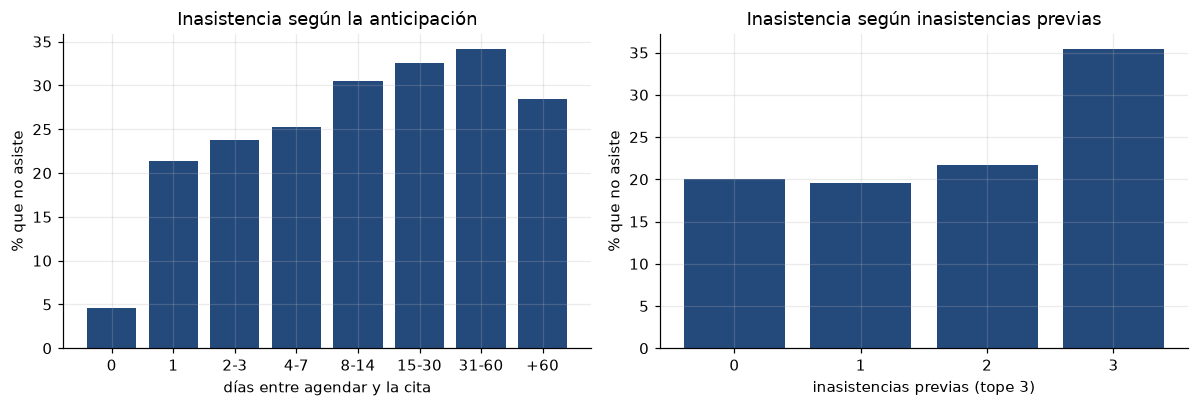

In [3]:
df = tns.preparar(df)
df = df.sort_values(["appt", "sched"]).reset_index(drop=True)
display(df[tns.FEATURES + ["lead_days", "y"]].describe().round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
tramos = pd.cut(df["lead_days"], [-1, 0, 1, 3, 7, 14, 30, 60, 400],
                labels=["0", "1", "2-3", "4-7", "8-14", "15-30", "31-60", "+60"])
t = df.groupby(tramos, observed=True)["y"].mean() * 100
ax[0].bar(t.index.astype(str), t.values, color=AZUL)
ax[0].set_title("Inasistencia según la anticipación")
ax[0].set_xlabel("días entre agendar y la cita"); ax[0].set_ylabel("% que no asiste")
t2 = df.groupby("prior_no_shows")["y"].mean() * 100
ax[1].bar(t2.index.astype(str), t2.values, color=AZUL)
ax[1].set_title("Inasistencia según inasistencias previas")
ax[1].set_xlabel("inasistencias previas (tope 3)"); ax[1].set_ylabel("% que no asiste")
plt.tight_layout(); plt.show()

## 3. Validación temporal (60 / 20 / 20)

No se mezclan las citas al azar: se **entrena con las más antiguas** y se **prueba con las más recientes**,
como ocurriría en el uso real. El tramo del medio sirve para calibrar.

,citas,tasa de inasistencia,desde,hasta
Entrenar (60 %),63529,0.209,2016-04-29,2016-05-19
Calibrar (20 %),20538,0.201,2016-05-20,2016-05-31
Probar (20 %),26449,0.185,2016-06-01,2016-06-08


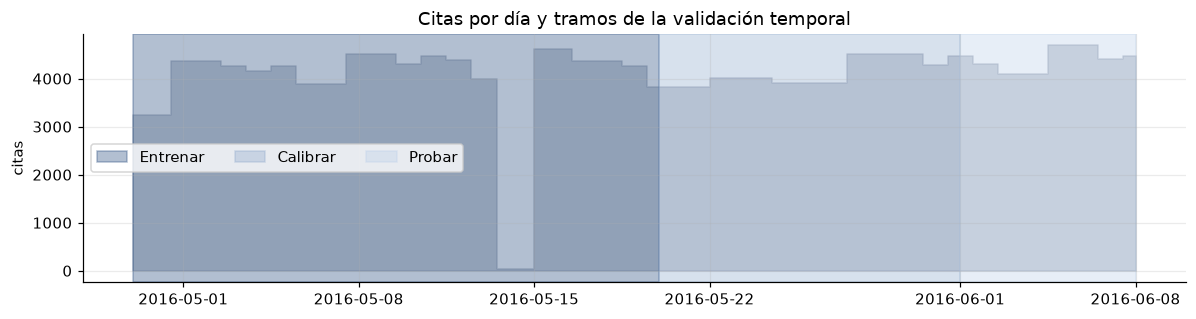

In [4]:
def corte(frac):
    return df.iloc[int(len(df) * frac)]["appt"]

c1, c2 = corte(0.60), corte(0.80)
train = df[df["appt"] < c1]
valid = df[(df["appt"] >= c1) & (df["appt"] < c2)]
test = df[df["appt"] >= c2]

resumen = pd.DataFrame({
    "citas": [len(train), len(valid), len(test)],
    "tasa de inasistencia": [round(x["y"].mean(), 3) for x in (train, valid, test)],
    "desde": [x["appt"].min().date() for x in (train, valid, test)],
    "hasta": [x["appt"].max().date() for x in (train, valid, test)],
}, index=["Entrenar (60 %)", "Calibrar (20 %)", "Probar (20 %)"])
display(resumen)

diario = df.groupby("appt").size()
fig, ax = plt.subplots(figsize=(11, 3))
ax.fill_between(diario.index, diario.values, color=GRIS, alpha=0.5, step="mid")
for ini, fin, col, nom in [(diario.index.min(), c1, AZUL, "Entrenar"), (c1, c2, CLARO, "Calibrar"), (c2, diario.index.max(), "#BCD0EA", "Probar")]:
    ax.axvspan(ini, fin, color=col, alpha=0.35, label=nom)
ax.set_title("Citas por día y tramos de la validación temporal"); ax.set_ylabel("citas"); ax.legend(ncol=3)
plt.tight_layout(); plt.show()

## 4. Entrenamiento: regresión logística + calibración de Platt

1. Se **estandarizan** las variables con la media y la desviación del tramo de entrenamiento.
2. Se ajusta la **regresión logística**.
3. La **calibración de Platt** se ajusta en el tramo de calibración, para que una probabilidad de 30 % signifique
   cerca de 30 % de inasistencias reales.

In [5]:
mu = train[tns.FEATURES].mean().values
sd = train[tns.FEATURES].std(ddof=0).replace(0, 1).values
z = lambda d: (d[tns.FEATURES].values - mu) / sd

lr = LogisticRegression(C=1.0, max_iter=1000).fit(z(train), train["y"])
logit = lambda d: lr.decision_function(z(d))

platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(valid).reshape(-1, 1), valid["y"])
a, b = float(platt.coef_[0][0]), float(platt.intercept_[0])
p_lr = lambda d: tns.sigmoid(a * logit(d) + b)

pesos = pd.Series(lr.coef_[0] / sd, index=tns.FEATURES)
display(pesos.round(3).to_frame("peso por unidad (log-odds)"))
print(f"Calibración de Platt: a = {a:.3f}, b = {b:.3f}")
print("Un peso positivo aumenta la probabilidad de inasistencia.")

,peso por unidad (log-odds)
lead_log,0.243
same_day,-1.534
prior_no_shows,0.454


Calibración de Platt: a = 1.054, b = -0.103
Un peso positivo aumenta la probabilidad de inasistencia.


## 5. Comparación con otras alternativas

Se compara contra una **regla simple** (la línea base que usaba el servicio antes del modelo) y contra
*gradient boosting*. Métricas: AUC-ROC, AUC-PR (la inasistencia es la clase minoritaria), Brier y ECE
(calibración), y recall y precisión al marcar el 20 % de citas con mayor riesgo.

,auc_roc,auc_pr,brier,ece,recall,precision,tasa_marcadas
Reglas simples,0.6175,0.2395,0.1518,0.0526,0.5885,0.2613,0.4158
Regresión logística calibrada,0.6990,0.2874,0.1395,0.0196,0.3095,0.3071,0.1860
Gradient boosting,0.7021,0.2854,0.1394,0.0345,0.3152,0.3074,0.1893
Azar,0.5000,0.1846,NaN,NaN,0.2000,0.1846,0.2000


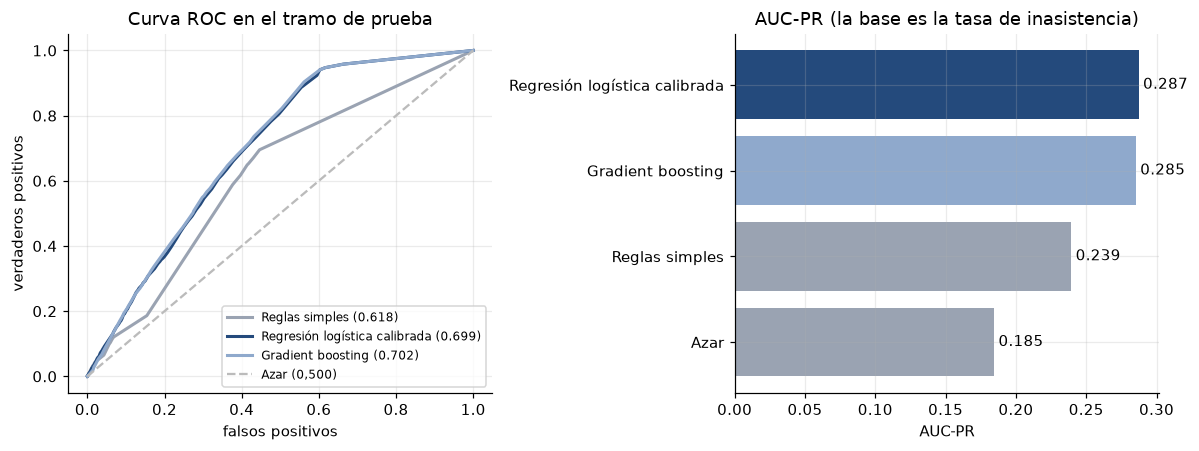

In [6]:
gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)
gb.fit(train[tns.FEATURES].values, train["y"])
p_gb = lambda d: gb.predict_proba(d[tns.FEATURES].values)[:, 1]

modelos = {"Reglas simples": tns.regla_v0, "Regresión logística calibrada": p_lr, "Gradient boosting": p_gb}
filas = {}
for nombre, fn in modelos.items():
    umbral = float(np.quantile(fn(valid), 1 - tns.FLAG_RATE))
    filas[nombre] = tns.metricas(test["y"].values, fn(test), umbral)

azar = float(test["y"].mean())
tabla = pd.DataFrame(filas).T[["auc_roc", "auc_pr", "brier", "ece", "recall", "precision", "tasa_marcadas"]]
tabla.loc["Azar"] = [0.5, round(azar, 4), np.nan, np.nan, tns.FLAG_RATE, round(azar, 4), tns.FLAG_RATE]
display(tabla)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for (nombre, fn), col in zip(modelos.items(), [GRIS, AZUL, CLARO]):
    fpr, tpr, _ = roc_curve(test["y"], fn(test))
    ax[0].plot(fpr, tpr, color=col, lw=2, label=f"{nombre} ({tabla.loc[nombre, 'auc_roc']:.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="#bbbbbb", label="Azar (0,500)")
ax[0].set_title("Curva ROC en el tramo de prueba"); ax[0].set_xlabel("falsos positivos"); ax[0].set_ylabel("verdaderos positivos"); ax[0].legend(loc="lower right", fontsize=8)
orden = ["Azar", "Reglas simples", "Gradient boosting", "Regresión logística calibrada"]
ax[1].barh(orden, tabla.loc[orden, "auc_pr"], color=[GRIS, GRIS, CLARO, AZUL])
ax[1].set_title("AUC-PR (la base es la tasa de inasistencia)"); ax[1].set_xlabel("AUC-PR")
for i, v in enumerate(tabla.loc[orden, "auc_pr"]):
    ax[1].text(v + 0.003, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

**Lectura honesta:** la regresión logística supera a las reglas y **iguala** a *gradient boosting* con variables tan simples,
por eso se eligió: es interpretable. La mejora sobre el azar es **moderada**; sirve para priorizar recordatorios,
no para predecir con certeza.

## 6. Calibración

Una probabilidad útil debe ser honesta: de las citas con 30 % estimado, cerca de 30 % deben terminar en inasistencia.

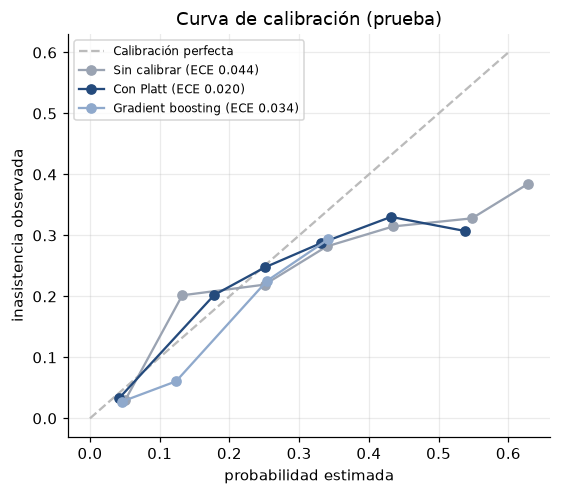

In [7]:
def curva(y, p, bins=10, minimo=50):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    xs, ys = [], []
    for k in range(bins):
        m = idx == k
        if m.sum() >= minimo:
            xs.append(p[m].mean()); ys.append(y[m].mean())
    return xs, ys

y_test = test["y"].values
sin_calibrar = tns.sigmoid(logit(test))
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 0.6], [0, 0.6], "--", color="#bbbbbb", label="Calibración perfecta")
for nombre, p, col in [("Sin calibrar", sin_calibrar, GRIS), ("Con Platt", p_lr(test), AZUL), ("Gradient boosting", p_gb(test), CLARO)]:
    xs, ys = curva(y_test, p)
    ax.plot(xs, ys, "o-", color=col, label=f"{nombre} (ECE {tns.ece(y_test, p):.3f})")
ax.set_xlabel("probabilidad estimada"); ax.set_ylabel("inasistencia observada"); ax.set_title("Curva de calibración (prueba)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Auditoría de equidad por subgrupos

Edad, sexo y beca **no** entran al modelo, pero se revisa si el modelo se equivoca más con algún grupo.

,variable,grupo,n,tasa_real,prob_media,tasa_marcadas,recall,precision
0,sexo,Female,9135,0.188,0.195,0.179,0.294,0.308
1,sexo,Male,17314,0.183,0.205,0.190,0.318,0.307
2,edad,0-17,6498,0.201,0.188,0.179,0.318,0.357
3,edad,18-29,3852,0.232,0.203,0.187,0.295,0.365
4,edad,30-59,10828,0.180,0.205,0.190,0.316,0.301
5,edad,60+,5271,0.138,0.210,0.187,0.296,0.220
6,beca,con_beca,2561,0.209,0.192,0.169,0.321,0.397
7,beca,sin_beca,23888,0.182,0.203,0.188,0.308,0.298


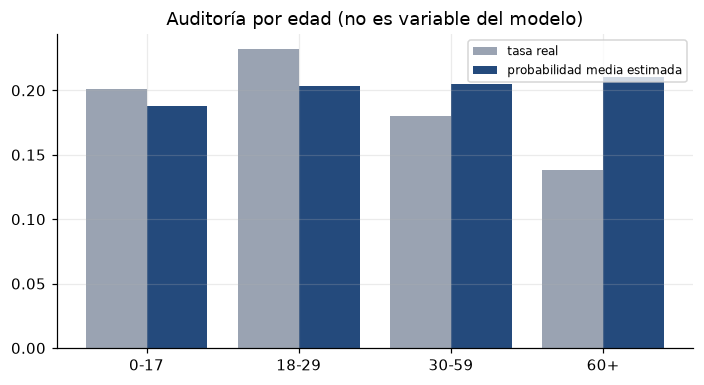

In [8]:
umbral_lr = float(np.quantile(p_lr(valid), 1 - tns.FLAG_RATE))
sub = tns.por_subgrupo(test, p_lr(test), umbral_lr)
aud = pd.DataFrame([{"variable": v, "grupo": g, **d} for v, gs in sub.items() for g, d in gs.items()])
display(aud)

e = aud[aud["variable"] == "edad"].reset_index(drop=True)
x = np.arange(len(e))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(x - 0.2, e["tasa_real"], 0.4, color=GRIS, label="tasa real")
ax.bar(x + 0.2, e["prob_media"], 0.4, color=AZUL, label="probabilidad media estimada")
ax.set_xticks(x); ax.set_xticklabels(e["grupo"]); ax.set_title("Auditoría por edad (no es variable del modelo)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

El modelo **sobreestima** el riesgo en personas de 60 años o más y lo **subestima** en 18–29, aunque no usa la edad.
Es una señal para vigilar y para reentrenar con datos propios, no para ignorar.

## 8. Coherencia con el modelo que usa el servicio

Dos comprobaciones: (1) las métricas de este cuaderno coinciden con las que guardó `train_no_show.py`, y
(2) el predictor real del servicio (`LogisticNoShowPredictor`, que carga `artifacts/no_show_logreg_v1.json`)
da las mismas probabilidades que el modelo entrenado aquí.

In [9]:
rep = json.loads((ML / "artifacts" / "metrics_v1.json").read_text(encoding="utf-8"))["metricas_test"]
for clave, nombre in [("reglas_v0", "Reglas simples"), ("regresion_logistica_calibrada", "Regresión logística calibrada"), ("gradient_boosting", "Gradient boosting")]:
    nb_v, guardado = tabla.loc[nombre, "auc_roc"], rep[clave]["auc_roc"]
    print(f"{nombre:32s} cuaderno={nb_v:.4f}  guardado={guardado:.4f}  {'OK' if abs(nb_v - guardado) < 1e-3 else 'DIFIERE'}")

from src.infrastructure.logistic_no_show import LogisticNoShowPredictor
servicio = LogisticNoShowPredictor(ML / "artifacts" / "no_show_logreg_v1.json")

muestra = test.sample(2000, random_state=0)
p_servicio = np.array([servicio.predict({"lead_days": int(r.lead_days), "prior_no_shows": int(r.prior_no_shows)})["probability"]
                       for r in muestra.itertuples()])
dif = np.abs(p_servicio - p_lr(muestra))
print(f"\nDiferencia máxima entre el servicio y el modelo entrenado (2 000 citas): {dif.max():.4f}")

Reglas simples                   cuaderno=0.6175  guardado=0.6175  OK
Regresión logística calibrada    cuaderno=0.6990  guardado=0.6990  OK
Gradient boosting                cuaderno=0.7021  guardado=0.7021  OK

Diferencia máxima entre el servicio y el modelo entrenado (2 000 citas): 0.0005


### Ejemplos con el predictor del servicio

Así responde el servicio para citas con distinta anticipación e historial. Es el mismo cálculo que ve el personal de UNAYOE.

In [10]:
casos = [(0, 0), (1, 0), (3, 0), (7, 0), (14, 0), (30, 0), (1, 1), (1, 2), (30, 2)]
ejemplos = pd.DataFrame([
    {"días de anticipación": d, "inasistencias previas": p,
     "probabilidad": servicio.predict({"lead_days": d, "prior_no_shows": p})["probability"],
     "factores": ", ".join(servicio.predict({"lead_days": d, "prior_no_shows": p})["factors"]) or "—"}
    for d, p in casos])
display(ejemplos)

,días de anticipación,inasistencias previas,probabilidad,factores
0,0,0,0.037,—
1,1,0,0.187,—
2,3,0,0.216,—
3,7,0,0.247,Cita agendada con mucha anticipación
4,14,0,0.278,Cita agendada con mucha anticipación
5,30,0,0.317,Cita agendada con mucha anticipación
6,1,1,0.271,Inasistencias previas
7,1,2,0.375,Inasistencias previas
8,30,2,0.547,"Cita agendada con mucha anticipación, Inasiste..."


## Límites

- Entrenado con **atención médica general en Brasil (2016)**, no con estudiantes: no hay evidencia de que funcione igual en la UNMSM.
- Solo usa anticipación e inasistencias previas; **sin historial** (arranque en frío) el desempeño se apoya casi solo en la anticipación.
- Es **orientativo**: sirve para decidir recordatorios y nunca para negar o retrasar una cita.
- **Siguiente paso:** reentrenar con el historial real (`appointment_events`) y medir si los recordatorios guiados reducen la inasistencia.